# **Estudo Independente 04** - Mini Projeto de Ciência de Dados

28-11-2026

**Nome:** Gabriel Schiavo

# **Mini Projeto de Ciência de Dados** — Postos de Confiança (Prefeitura de Porto Alegre)

## Problema e Objetivos
**Contexto:** A Prefeitura de Porto Alegre possui vagas preenchidas por indicação: *Funções Gratificadas (FG)* (exclusivas para servidores concursados), *Cargos em Comissão (CC)* (livre nomeação) e *Subsídios* (prefeito, vice e secretários).

**Objetivo:** Analisar a distribuição e o tempo de vigência dos postos de confiança da prefeitura respondendo a 3 questões:
1. Qual é a proporção entre os tipos de postos (FG, CC e Subsídio)?
2. Quais secretarias concentram o maior número de vagas?
3. Qual é o tempo de vigência dessas vagas e como elas evoluíram ao longo dos anos?

## 1. Obtenção dos dados


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Configuração visual dos gráficos
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, LARANJA, CINZA = "#2a6f97", "#e07a5f", "#8d99ae"

# Leitura direta do CSV do Portal de Dados Abertos de POA
url_csv = "https://dadosabertos.poa.br/dataset/bc544f64-5e86-4a60-8dcb-527c06a24021/resource/bd7dcbce-7800-43bc-a80c-b4a2c012ac76/download/postos_confianca.csv"
df_raw = pd.read_csv(url_csv, sep=";")

print(f"Total de registros: {df_raw.shape[0]} linhas e {df_raw.shape[1]} colunas.")
df_raw.head()

Total de registros: 2853 linhas e 8 colunas.


,data_extracao,secretaria,descricao,numero_vaga,nivel,lei,dtini,dtfim
0,2026-10-01 00:00:00,SMC,SECRETARIO MUNICIPAL,1000980,SUBSIDIO,LE,2005-07-01 00:00:00,NaN
1,2026-10-01 00:00:00,SMSEG,SECRETARIO MUNICIPAL,1001905,SUBSIDIO,LE,2005-07-01 00:00:00,NaN
2,2026-10-01 00:00:00,SMS,SECRETARIO MUNICIPAL,1001172,SUBSIDIO,LE,2005-07-01 00:00:00,NaN
3,2026-10-01 00:00:00,GP,PREFEITO,1000001,SUBSIDIO,LOM,2005-07-01 00:00:00,NaN
4,2026-10-01 00:00:00,GP,VICE-PREFEITO,1000002,SUBSIDIO,LOM,2005-07-01 00:00:00,NaN


## 2. Preparação e Tratamento dos Dados
* **Conversão de tipos:** Transformação das colunas de texto (`data_extracao`, `dtini`, `dtfim`) para o formato `datetime`.
* **Valores ausentes:** A coluna `dtfim` possui 99,9% de valores nulos (`NaN`), o que não é um erro: indica que a vaga segue **ativa (vigente)**.
* **Engenharia de atributos:** Criação das colunas `tipo_posto` (agrupando níveis em FG, CC ou Subsídio), `ano_inicio` e `tempo_vigencia_anos`.

In [ ]:
df = df_raw.copy()

# 1. Conversão das colunas de data
for col in ["data_extracao", "dtini", "dtfim"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# 2. Padronização de textos
df["secretaria"] = df["secretaria"].str.strip().str.upper()
df["nivel"] = df["nivel"].str.strip().str.upper()

# 3. Criação da categoria Tipo de Posto
def classificar_posto(nivel):
    if str(nivel).startswith("FG"): return "Função Gratificada (FG)"
    if str(nivel).startswith("CC"): return "Cargo em Comissão (CC)"
    return "Subsídio"

df["tipo_posto"] = df["nivel"].apply(classificar_posto)

# 4. Criação das variáveis de tempo
df["ano_inicio"] = df["dtini"].dt.year
data_final = df["dtfim"].fillna(df["data_extracao"])
df["tempo_vigencia_anos"] = ((data_final - df["dtini"]).dt.days / 365.25).round(2)

# Verificando valores nulos e tipos após o tratamento
print("Valores ausentes por coluna:\n", df[["secretaria", "nivel", "dtini", "dtfim"]].isna().sum())
df[["secretaria", "descricao", "nivel", "tipo_posto", "ano_inicio", "tempo_vigencia_anos"]].head()

Valores ausentes por coluna:
 secretaria       0
nivel            0
dtini            0
dtfim         2852
dtype: int64


,secretaria,descricao,nivel,tipo_posto,ano_inicio,tempo_vigencia_anos
0,SMC,SECRETARIO MUNICIPAL,SUBSIDIO,Subsídio,2005,21.25
1,SMSEG,SECRETARIO MUNICIPAL,SUBSIDIO,Subsídio,2005,21.25
2,SMS,SECRETARIO MUNICIPAL,SUBSIDIO,Subsídio,2005,21.25
3,GP,PREFEITO,SUBSIDIO,Subsídio,2005,21.25
4,GP,VICE-PREFEITO,SUBSIDIO,Subsídio,2005,21.25


## 3. Análise Exploratória (Estatísticas Descritivas)
Avaliamos a proporção de vagas por modalidade e o comportamento do tempo de duração (média e mediana) em cada grupo.

In [ ]:
print(f"Órgãos (Secretarias) distintos: {df['secretaria'].nunique()}")
print(f"Vagas vigentes (sem data de fim): {df['dtfim'].isna().sum()} de {len(df)}\n")

# Tabela de frequência por tipo de posto
resumo_tipos = df["tipo_posto"].value_counts().to_frame("Vagas")
resumo_tipos["%"] = (resumo_tipos["Vagas"] / len(df) * 100).round(1)
print("--- Distribuição por Tipo de Posto ---")
print(resumo_tipos)

# Estatísticas de tempo de vigência por tipo
print("\n--- Tempo de Vigência ( em Anos) por Tipo ---")
print(df.groupby("tipo_posto")["tempo_vigencia_anos"].agg(["count", "mean", "median", "max"]).round(2))

Órgãos (Secretarias) distintos: 21
Vagas vigentes (sem data de fim): 2852 de 2853

--- Distribuição por Tipo de Posto ---
                         Vagas     %
tipo_posto                          
Função Gratificada (FG)   2056  72.1
Cargo em Comissão (CC)     773  27.1
Subsídio                    24   0.8

--- Tempo de Vigência ( em Anos) por Tipo ---
                         count   mean  median    max
tipo_posto                                          
Cargo em Comissão (CC)     773   0.75    0.35   1.66
Função Gratificada (FG)   2056   2.92    1.66  21.25
Subsídio                    24  10.19    6.69  21.25


## 4. Construção de Visualizações

### 4.1. Gráficos 1 e 2: Composição e Concentração

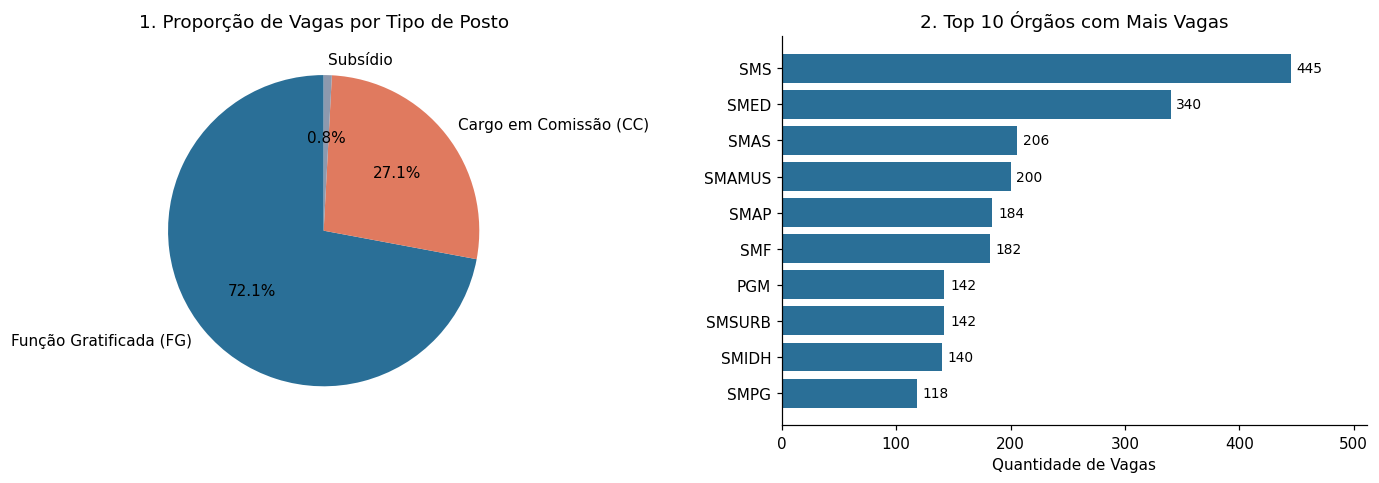

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Gráfico 1: Proporção por Tipo de Posto
tipos = df["tipo_posto"].value_counts()
ax[0].pie(tipos.values, labels=tipos.index, autopct="%1.1f%%", startangle=90, colors=[AZUL, LARANJA, CINZA])
ax[0].set_title("1. Proporção de Vagas por Tipo de Posto")

# Gráfico 2: Top 10 Secretarias com mais vagas
top10 = df["secretaria"].value_counts().head(10).sort_values()
ax[1].barh(top10.index, top10.values, color=AZUL)
for i, v in enumerate(top10.values):
    ax[1].text(v + 5, i, str(v), va="center", fontsize=9)
ax[1].set_title("2. Top 10 Órgãos com Mais Vagas")
ax[1].set_xlabel("Quantidade de Vagas")
ax[1].set_xlim(0, top10.max() * 1.15)

plt.tight_layout()
plt.show()

### 4.2. Gráfico 3: Evolução Histórica

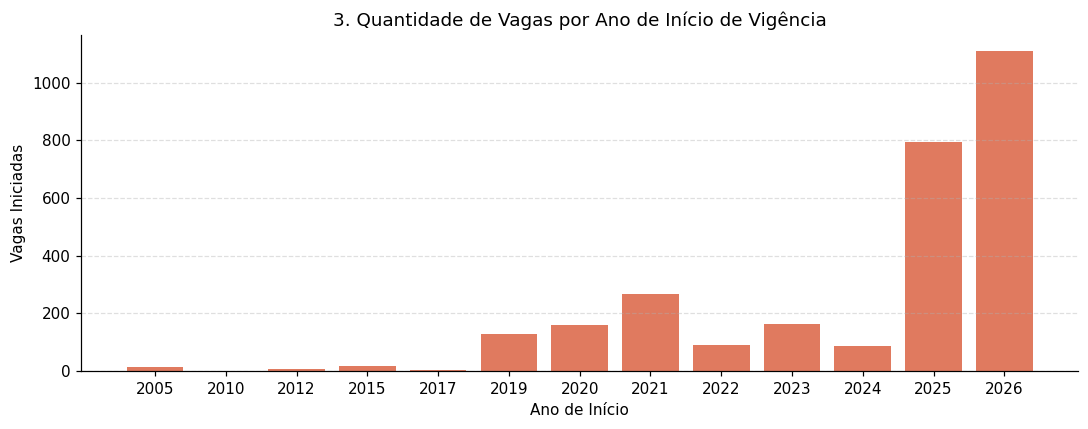

In [ ]:
por_ano = df["ano_inicio"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
plt.bar(por_ano.index.astype(str), por_ano.values, color=LARANJA)
plt.title("3. Quantidade de Vagas por Ano de Início de Vigência")
plt.xlabel("Ano de Início")
plt.ylabel("Vagas Iniciadas")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 5. Interpretação dos Resultados e Conclusões

A partir da análise dos **2.853 postos de confiança** da Prefeitura de Porto Alegre (extraídos em outubro de 2026), chegamos às seguintes conclusões:

1. **Predominância de servidores de carreira (FG):** A maior parte da estrutura de confiança (**72,1%**, ou 2.056 vagas) é composta por *Funções Gratificadas (FG)*, destinadas a servidores concursados. Os *Cargos em Comissão (CC)* representam **27,1%** (773 vagas), e os *Subsídios* (alta gestão) apenas **0,8%** (24 vagas).
2. **Concentração nas áreas operacionais:** Das 21 secretarias municipais, a **Saúde (SMS)** com 445 vagas e a **Educação (SMED)** lideram com folga o volume de postos. Isso ocorre porque essas pastas gerenciam dezenas de postos de saúde e escolas, demandando diversas chefias de equipe (majoritariamente FGs).
3. **Renovação e Tempo de Vigência:** A mediana geral de vigência das vagas é baixa (**1,07 anos**), com média de **2,39 anos**. Ao cruzar os tipos de posto, nota-se que os Cargos em Comissão (CC) são muito mais recentes (mediana de **0,35 anos** / ~4 meses de vigência), refletindo reformas administrativas recentes nos anos de 2025 e 2026, enquanto as Funções Gratificadas possuem maior estabilidade (média de **2,92 anos**).